In [ ]:
# Tugas Mandiri Pertemuan 5
# Eksplorasi Format File Tanpa Pandas

print("Tugas Mandiri Pertemuan 5")
print("Eksplorasi Format File dan Representasi Data")

Tugas Mandiri Pertemuan 5
Eksplorasi Format File dan Representasi Data


In [ ]:
import pandas as pd
import os

# Define the file path
file_path = '/content/dataset-kantin-bersih.csv'

# Check if the file exists
if not os.path.exists(file_path):
    print(f"Error: File '{file_path}' not found.")
    print("Please upload 'dataset-kantin-bersih.csv' to your Colab environment by clicking the 'Files' icon on the left sidebar, then 'Upload to session storage'.")
    print("Alternatively, if the file is in Google Drive, make sure it is correctly mounted and the path is adjusted accordingly.")
else:
    # Read the CSV file
    df = pd.read_csv(file_path)

    # Menghapus kolom kosong
    df = df.loc[:, ~df.columns.str.startswith('Unnamed')]

    print("Dataset berhasil dibaca!")
    print(df.head(5).to_string(index=False))


Dataset berhasil dibaca!
ID_Transaksi Waktu_Pesan Menu_Dipesan  Total_Pembayaran Metode_Bayar  Jumlah_Staf_Dapur  Waktu_Tunggu
       TX001       11:30  Nasi Goreng             15000         QRIS                4.0           8.0
       TX002       11:45  Ayam Geprek             12000         QRIS                4.0          10.0
       TX003       12:00   Mie Goreng             10000        TUNAI                3.0          10.0
       TX005       12:10  Ayam Geprek             12000         QRIS                3.0          15.0
       TX007       12:20  Nasi Goreng             15000        TUNAI                4.0          12.0


In [ ]:
df.to_json(
    'dataset-kantin-bersih.json',
    orient='records',
    indent=2
)

print("File JSON berhasil dibuat!")

File JSON berhasil dibuat!


In [ ]:
df.to_xml(
    'dataset-kantin-bersih.xml',
    index=False
)

print("File XML berhasil dibuat!")

File XML berhasil dibuat!


In [ ]:
import json

with open('dataset-kantin-bersih.json', 'r') as file:
    data_json = json.load(file)

print("JSON berhasil dibaca tanpa Pandas!")

JSON berhasil dibaca tanpa Pandas!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
print("ID Transaksi dan Menu yang Dipesan:")

for transaksi in data_json:
    print(transaksi['ID_Transaksi'], "-", transaksi['Menu_Dipesan'])


ID Transaksi dan Menu yang Dipesan:
TX001 - Nasi Goreng
TX002 - Ayam Geprek
TX003 - Mie Goreng
TX005 - Ayam Geprek
TX007 - Nasi Goreng
TX008 - Mie Goreng
TX009 - Nasi Goreng
TX010 - Ayam Geprek
TX011 - Nasi Goreng
TX012 - Mie Goreng
TX013 - Ayam Geprek
TX014 - Nasi Goreng
TX015 - Gorengan
TX017 - Ayam Geprek
TX018 - Mie Goreng
TX019 - Nasi Goreng
TX020 - Nasi Goreng
TX021 - Ayam Geprek
TX022 - Mie Goreng
TX023 - Gorengan
TX024 - Ayam Geprek
TX025 - Nasi Goreng
TX026 - Ayam Geprek
TX027 - Mie Goreng
TX028 - Ayam Geprek
TX029 - Gorengan


In [ ]:
print("""
KESIMPULAN

Data kantin bersih dalam format CSV berhasil diekspor
menjadi format JSON dan XML menggunakan Pandas.

File JSON kemudian berhasil dibaca menggunakan library
json tanpa menggunakan Pandas.

ID transaksi dan menu yang dipesan berhasil ditampilkan
menggunakan perulangan (loop) Python.
""")


KESIMPULAN

Data kantin bersih dalam format CSV berhasil diekspor
menjadi format JSON dan XML menggunakan Pandas.

File JSON kemudian berhasil dibaca menggunakan library
json tanpa menggunakan Pandas.

ID transaksi dan menu yang dipesan berhasil ditampilkan
menggunakan perulangan (loop) Python.



# PERTEMUAN 6 — MANAJEMEN BASIS DATA & SQL

Pada bagian ini dilakukan pembuatan database SQLite dan pengolahan
dataset kantin bersih menggunakan query SQL.

## 1. Membaca Dataset Kantin Bersih
Pada tahap ini, dataset kantin yang sudah bersih dibaca menggunakan Python dengan library Pandas. Dataset ini akan digunakan sebagai sumber data untuk membuat database SQLite dan melakukan query SQL.

In [ ]:
# 1.Membaca dataset kantin bersih

import pandas as pd
import sqlite3

df = pd.read_csv('/content/dataset-kantin-bersih.csv')

print("Dataset berhasil dibaca!")
print(df.head())
display(df.head())

Dataset berhasil dibaca!
  ID_Transaksi Waktu_Pesan Menu_Dipesan  Total_Pembayaran Metode_Bayar  \
0        TX001       11:30  Nasi Goreng             15000         QRIS   
1        TX002       11:45  Ayam Geprek             12000         QRIS   
2        TX003       12:00   Mie Goreng             10000        TUNAI   
3        TX005       12:10  Ayam Geprek             12000         QRIS   
4        TX007       12:20  Nasi Goreng             15000        TUNAI   

   Jumlah_Staf_Dapur  Waktu_Tunggu  
0                4.0           8.0  
1                4.0          10.0  
2                3.0          10.0  
3                3.0          15.0  
4                4.0          12.0  


,ID_Transaksi,Waktu_Pesan,Menu_Dipesan,Total_Pembayaran,Metode_Bayar,Jumlah_Staf_Dapur,Waktu_Tunggu
0,TX001,11:30,Nasi Goreng,15000,QRIS,4.0,8.0
1,TX002,11:45,Ayam Geprek,12000,QRIS,4.0,10.0
2,TX003,12:00,Mie Goreng,10000,TUNAI,3.0,10.0
3,TX005,12:10,Ayam Geprek,12000,QRIS,3.0,15.0
4,TX007,12:20,Nasi Goreng,15000,TUNAI,4.0,12.0


## 2. Membuat Database SQLite

Pada tahap ini, dataset kantin bersih dimasukkan ke dalam database SQLite dengan nama kantin_polinela.db. Data disimpan dalam tabel transaksi agar dapat diolah menggunakan query SQL.

In [ ]:
# 2. Membuat Database SQLite

conn = sqlite3.connect('kantin_polinela.db')

df.to_sql(
    'transaksi',
    conn,
    if_exists='replace',
    index=False
)

print("Database kantin_polinela.db berhasil dibuat!")

Database kantin_polinela.db berhasil dibuat!


## 3. Mengecek Isi Database

Pada tahap ini dilakukan pengecekan untuk memastikan data dari dataset kantin bersih sudah berhasil dimasukkan ke dalam tabel transaksi pada database.

In [ ]:
# 3. Mengecek Isi Database

query_cek = """
SELECT *
FROM transaksi;
"""

hasil_cek = pd.read_sql_query(query_cek, conn)

print(hasil_cek)
display(hasil_cek)

   ID_Transaksi Waktu_Pesan Menu_Dipesan  Total_Pembayaran Metode_Bayar  \
0         TX001       11:30  Nasi Goreng             15000         QRIS   
1         TX002       11:45  Ayam Geprek             12000         QRIS   
2         TX003       12:00   Mie Goreng             10000        TUNAI   
3         TX005       12:10  Ayam Geprek             12000         QRIS   
4         TX007       12:20  Nasi Goreng             15000        TUNAI   
5         TX008       12:30   Mie Goreng             10000         QRIS   
6         TX009       12:35  Nasi Goreng             15000         QRIS   
7         TX010       12:40  Ayam Geprek             12000        TUNAI   
8         TX011       12:45  Nasi Goreng             15000         QRIS   
9         TX012       12:50   Mie Goreng             10000        TUNAI   
10        TX013       12:55  Ayam Geprek             12000         QRIS   
11        TX014       13:00  Nasi Goreng             15000        TUNAI   
12        TX015       13:

,ID_Transaksi,Waktu_Pesan,Menu_Dipesan,Total_Pembayaran,Metode_Bayar,Jumlah_Staf_Dapur,Waktu_Tunggu
0,TX001,11:30,Nasi Goreng,15000,QRIS,4.0,8.0
1,TX002,11:45,Ayam Geprek,12000,QRIS,4.0,10.0
2,TX003,12:00,Mie Goreng,10000,TUNAI,3.0,10.0
3,TX005,12:10,Ayam Geprek,12000,QRIS,3.0,15.0
4,TX007,12:20,Nasi Goreng,15000,TUNAI,4.0,12.0
5,TX008,12:30,Mie Goreng,10000,QRIS,5.0,7.0
6,TX009,12:35,Nasi Goreng,15000,QRIS,5.0,8.0
7,TX010,12:40,Ayam Geprek,12000,TUNAI,5.0,25.0
8,TX011,12:45,Nasi Goreng,15000,QRIS,5.0,6.0
9,TX012,12:50,Mie Goreng,10000,TUNAI,5.0,18.0


## 4. SQL Query 1 — Waktu Tunggu Maksimum setiap Menu
Query ini digunakan untuk mengetahui waktu tunggu maksimum yang tercatat pada setiap menu. Hasil query diurutkan dari waktu tunggu paling lama ke yang paling singkat.

In [ ]:
# 4. SQL Query 1 - Waktu Tunggu Maksimum Setiap Menu

query_sql1 = """
SELECT
    Menu_Dipesan,
    MAX(Waktu_Tunggu) AS Waktu_Tunggu_Terlama
FROM transaksi
GROUP BY Menu_Dipesan
ORDER BY Waktu_Tunggu_Terlama DESC;
"""

hasil_sql1 = pd.read_sql_query(query_sql1, conn)

print("HASIL QUERY 1:")
display(hasil_sql1)

HASIL QUERY 1:


,Menu_Dipesan,Waktu_Tunggu_Terlama
0,Ayam Geprek,25.0
1,Nasi Goreng,22.0
2,Mie Goreng,18.0
3,Gorengan,15.0


## 5. SQL Query 2 — Jumlah Transaksi setiap menu dan Metode Pembayaran
Query ini digunakan untuk mengetahui jumlah transaksi pada setiap menu berdasarkan metode pembayaran yang digunakan. Hasilnya dikelompokkan berdasarkan menu dan metode pembayaran.

In [ ]:
# 5. SQL Query 2 - Jumlah Transaksi setiap Menu dan Metode Pembayaran

query_sql2 = """
SELECT
    Menu_Dipesan,
    Metode_Bayar,
    COUNT(*) AS Jumlah_Transaksi
FROM transaksi
GROUP BY Menu_Dipesan, Metode_Bayar
ORDER BY Jumlah_Transaksi DESC;
"""

hasil_sql2 = pd.read_sql_query(query_sql2, conn)

print("HASIL QUERY 2:")
display(hasil_sql2)

HASIL QUERY 2:


,Menu_Dipesan,Metode_Bayar,Jumlah_Transaksi
0,Ayam Geprek,QRIS,7
1,Nasi Goreng,QRIS,5
2,Mie Goreng,TUNAI,4
3,Nasi Goreng,TUNAI,3
4,Ayam Geprek,TUNAI,2
5,Gorengan,TUNAI,2
6,Mie Goreng,QRIS,2
7,Gorengan,QRIS,1


# PERTEMUAN 7 — VISUALISASI DATA
Pada bagian ini dilakukan visualisasi data kantin menggunakan Python.
Visualisasi yang dibuat terdiri dari Bar Chart, Histogram, dan Scatterplot.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

## Visualisasi 1 — Bar Chart Menu yang Dipesan

Bar Chart digunakan untuk melihat jumlah transaksi berdasarkan menu yang dipesan. Grafik ini membantu mengetahui menu yang paling sering dipilih oleh pelanggan kantin.

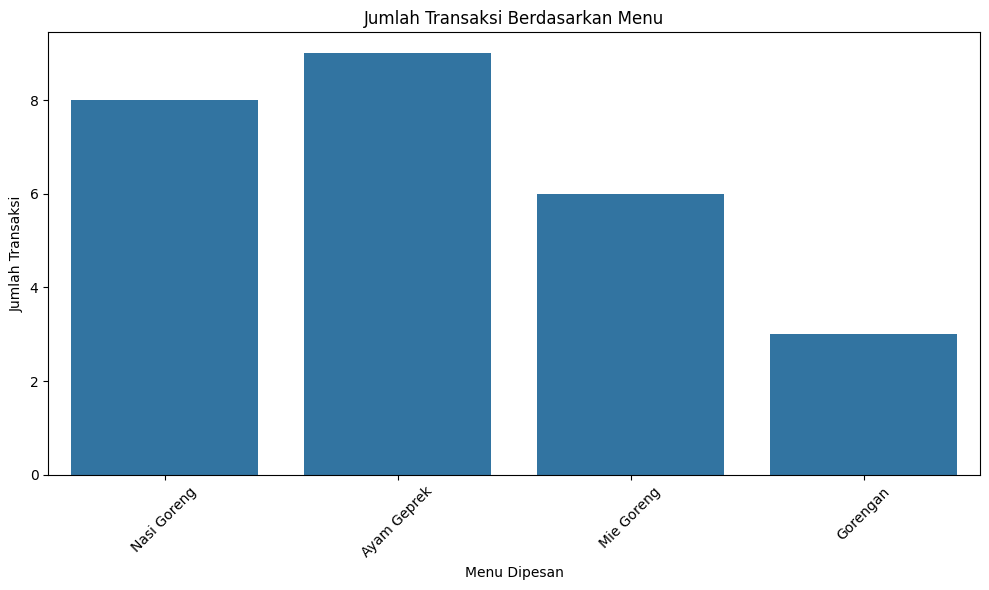

In [ ]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x='Menu_Dipesan'
)

plt.title('Jumlah Transaksi Berdasarkan Menu')
plt.xlabel('Menu Dipesan')
plt.ylabel('Jumlah Transaksi')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Visualisasi 2 — Histogram Total Pembayaran

Histogram digunakan untuk melihat distribusi total pembayaran pada transaksi kantin. Grafik ini membantu mengetahui rentang nilai pembayaran yang paling sering terjadi.

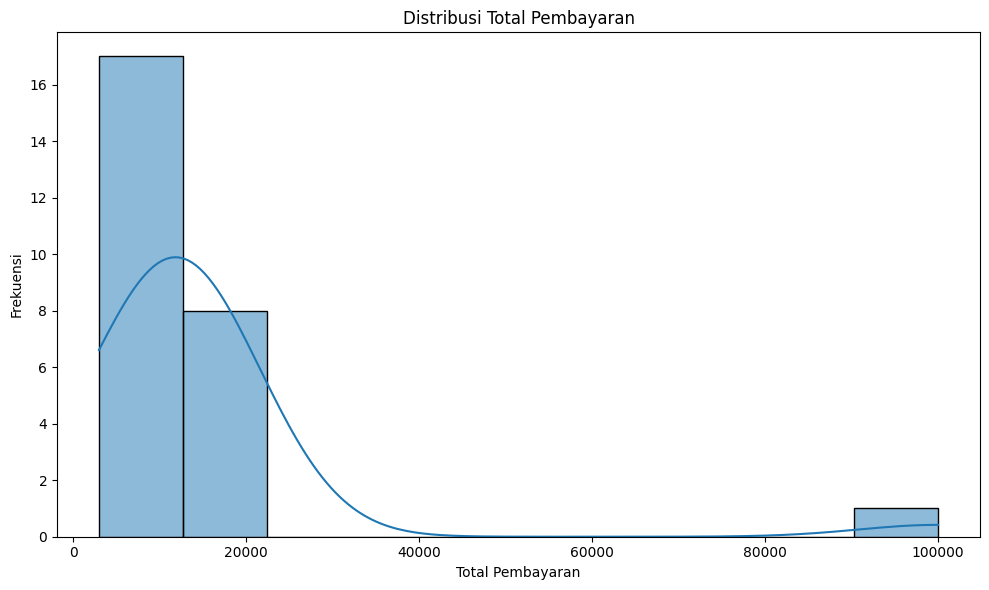

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='Total_Pembayaran',
    bins=10,
    kde=True
)

plt.title('Distribusi Total Pembayaran')
plt.xlabel('Total Pembayaran')
plt.ylabel('Frekuensi')

plt.tight_layout()
plt.show()

## Visualisasi 3 — Boxplot Menu Dipesan vs Total Pembayaran

Boxplot digunakan untuk membandingkan distribusi total pembayaran pada setiap menu yang dipesan. Grafik ini dapat menunjukkan median, sebaran data, serta kemungkinan adanya outlier pada total pembayaran untuk masing-masing menu.

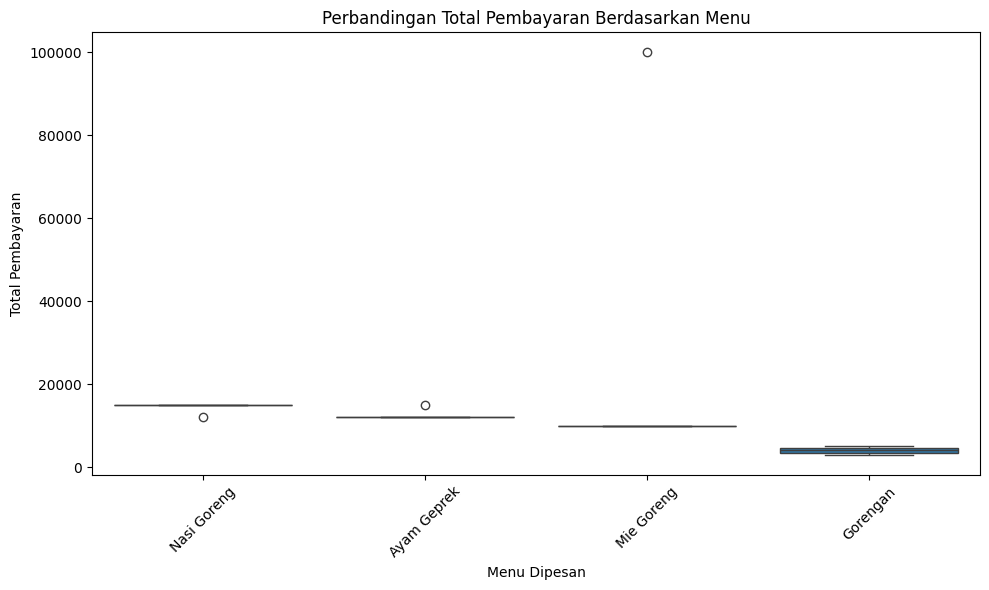

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='Menu_Dipesan',
    y='Total_Pembayaran'
)

plt.title('Perbandingan Total Pembayaran Berdasarkan Menu')
plt.xlabel('Menu Dipesan')
plt.ylabel('Total Pembayaran')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

#TUGAS LATIHAN PENGEMBANGAN MAHASISWA PERTEMUAN 9

In [ ]:
# 1.import library sains data & Scipy
import numpy as np
import scipy.stats as stats


In [ ]:
# 2. Data Sampel Waktu Tunggu Kantin (Menit)
qris = np.array([8, 10, 9, 12, 11, 7, 10, 9, 11, 8])
tunai = np.array([15, 18, 14, 16, 20, 15, 17, 19, 14, 16])

In [ ]:
# 3. Langkah awal A : Uji Normalitas (Alpha=0,05)
S1,p_norm = stats.normaltest(qris)
print('p-value Normalitas QRIS:', round(p_norm,4))


p-value Normalitas QRIS: 0.4841


In [ ]:
# 4. Langkah Awal B: Uji-t Independent
S2, p_val = stats.ttest_ind(qris, tunai)
print('p-value t-Test QRIS vs Tunai:', round(p_val, 5))
if p_val < 0.05: print('=> HASIL: BEDA SIGNIFIKAN!')

p-value t-Test QRIS vs Tunai: 0.0
=> HASIL: BEDA SIGNIFIKAN!


In [ ]:
# Data waktu tunggu pemesanan melalui aplikasi
waktu_app = np.array([5, 6, 7, 8, 5, 7, 6, 8, 6])

In [ ]:
# Membandingkan waktu tunggu QRIS dengan aplikasi
s3, p_app = stats.ttest_ind(qris, waktu_app)

print('p-value t-Test QRIS vs Aplikasi:', round(p_app, 5))

p-value t-Test QRIS vs Aplikasi: 0.00017


#PERTEMUAN 10: OVERVIEW MACHINE LEARNING & REKAYASA FITUR


In [ ]:
# 1. Load Data Kantin Polinela
import pandas as pd
from sklearn.preprocessing import StandardScaler

df = pd.DataFrame({
    'metode_bayar': ['QRIS', 'Tunai', 'QRIS', 'Tunai'],
    'total_bayar': [15000, 10000, 25000, 12000],
    'jam_pesan': [12.15, 11.30, 12.05, 13.10],
    'biaya_sewa_kos': [500000, 800000, 1200000, 1500000]
})

print(df)
display(df)

  metode_bayar  total_bayar  jam_pesan  biaya_sewa_kos
0         QRIS        15000      12.15          500000
1        Tunai        10000      11.30          800000
2         QRIS        25000      12.05         1200000
3        Tunai        12000      13.10         1500000


,metode_bayar,total_bayar,jam_pesan,biaya_sewa_kos
0,QRIS,15000,12.15,500000
1,Tunai,10000,11.30,800000
2,QRIS,25000,12.05,1200000
3,Tunai,12000,13.10,1500000


In [ ]:
# 2. Rekayasa Fitur A: One-Hot Encoding Teks

df_encoded = pd.get_dummies(
    df,
    columns=['metode_bayar']
)

In [ ]:
# 3. Rekayasa Fitur B: Feature Scaling (StandardScaler)

scaler = StandardScaler()

df_encoded[['bayar_scaled']] = scaler.fit_transform(
    df_encoded[['total_bayar']]
)

In [ ]:
# 4. Rekayasa Fitur C: Binning Jam Pesan (pd.cut)

df_encoded['kategori_jam'] = pd.cut(
    df_encoded['jam_pesan'],
    bins=[0, 11.5, 13.0, 24],
    labels=['Pagi', 'Jam Sibuk', 'Sore']
)
print(df_encoded[['bayar_scaled', 'kategori_jam']])
display(df_encoded[['bayar_scaled','kategori_jam']])

   bayar_scaled kategori_jam
0     -0.086711    Jam Sibuk
1     -0.953821         Pagi
2      1.647509    Jam Sibuk
3     -0.606977         Sore


,bayar_scaled,kategori_jam
0,-0.086711,Jam Sibuk
1,-0.953821,Pagi
2,1.647509,Jam Sibuk
3,-0.606977,Sore


In [ ]:
# 5. MinMaxScaler pada biaya sewa kos

from sklearn.preprocessing import MinMaxScaler

scaler_kos = MinMaxScaler()

df['biaya_kos_scaled'] = scaler_kos.fit_transform(
    df[['biaya_sewa_kos']]
)

print(df[['biaya_sewa_kos', 'biaya_kos_scaled']])

   biaya_sewa_kos  biaya_kos_scaled
0          500000               0.0
1          800000               0.3
2         1200000               0.7
3         1500000               1.0


In [ ]:
# 6. Binning Biaya Kos menjadi 3 kategori

df['Binning Biaya Kos'] = pd.cut(
    df['biaya_sewa_kos'],
    bins=[0, 600000, 1200000, float('inf')],
    labels=['Murah', 'Sedang', 'Mahal']
)

print(df[['biaya_sewa_kos', 'biaya_kos_scaled', 'Binning Biaya Kos']])

   biaya_sewa_kos  biaya_kos_scaled Binning Biaya Kos
0          500000               0.0             Murah
1          800000               0.3            Sedang
2         1200000               0.7            Sedang
3         1500000               1.0             Mahal


PERTEMUAN 11 MACHINE LEARNING :KLASIFIKASI

In [ ]:
# KODE STARTER KLASIFIKASI (DATAFRAME)

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier


In [ ]:
# 1.Dataset Transaksi kantin Dengan Dataframe
df = pd.DataFrame({
    "Waktu_Tunggu": [5.0, 12.5, 25.0, 8.0, 18.0, 3.0, 15.0, 2.0, 22.0],
    "Total_Bayar":  [10000, 15000, 25000, 12000, 30000, 8000, 20000, 5000, 28000],
    "Kategori_Besar": [0, 0, 1, 0, 1, 0, 1, 0, 1] # 1=Besar, 0=Biasa
})#


In [ ]:
# 2. Fitur x dan Target y dari dataframe
X = df[["Waktu_Tunggu", "Total_Bayar"]]
y = df["Kategori_Besar"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [ ]:
# 3. Train-Test split (80/20)
model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
akurasi_logistic = accuracy_score(y_test, y_pred)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

# 4. Fit Model & Evaluasi Akurasi Logistic Regression

model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Akurasi Model:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Akurasi Model: 1.0
Confusion Matrix:
[[2]]


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


# 5. Membuat model KNN dengan n_neighbors = 3

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
# Membuat model KNN dengan n_neighbors = 3

knn_model = KNeighborsClassifier(n_neighbors=3)

# 6. Melatih model KNN

In [ ]:
# 6. Melatih model KNN

knn_model.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

# 7. Prediksi menggunakan model KNN


In [ ]:
# 7. Prediksi menggunakan model KNN
y_pred_knn = knn_model.predict(X_test)

# 8. Menghitung akurasi KNN


In [ ]:
# 8. Menghitung akurasi KNN
akurasi_knn = accuracy_score(y_test, y_pred_knn)
print("\nAkurasi KNN:",
      akurasi_knn)


Akurasi KNN: 1.0


# 9. Confusion Matrix KNN


In [ ]:
print("Confusion Matrix KNN:")

print(confusion_matrix(y_test, y_pred_knn))

Confusion Matrix KNN:
[[2]]


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


# 10. Perbandingan akurasi

In [ ]:
print("\n=== PERBANDINGAN AKURASI ===")
print("Logistic Regression :", akurasi_logistic)
print("KNN                 :", akurasi_knn)


=== PERBANDINGAN AKURASI ===
Logistic Regression : 1.0
KNN                 : 1.0


**PERTEMUAN 12 : REGRESI**

In [ ]:
# KODE STARTER REGRESI LINEAR (DATAFRAME)
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
# 1. Dataset Regresi dengan DataFrame
df = pd.DataFrame({
    "Total_Bayar":  [10000, 15000, 25000, 12000, 30000, 8000, 20000, 5000, 28000],
    "Jumlah_Staf":  [2, 2, 3, 2, 4, 1, 3, 1, 4],
    "Waktu_Tunggu": [8.5, 12.0, 18.5, 10.0, 22.0, 6.0, 15.0, 4.5, 20.0] # Menit
})

In [ ]:
# 2. Fitur X dan Target y dari DataFrame
X = df[["Total_Bayar", "Jumlah_Staf"]]
y = df["Waktu_Tunggu"]

In [ ]:
# 3. Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
  X, y, test_size=0.2, random_state=42
  )

In [ ]:
# 4. Fit Model & Evaluasi MSE & R2
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
print("RMSE (Meleset Menit):", np.sqrt(mse))
print("R-Squared (R2 Score):", r2_score(y_test, y_pred))

RMSE (Meleset Menit): 0.44426705391757393
R-Squared (R2 Score): 0.9859645713637973


TAHAP PENGEMBANGAN DIRI

MEMBUAT DATA KOS SENDIRI BUKAN DARI PPT UNTUK ITU DI KEMBANGKAN **bold text**

In [ ]:
# 5. Membuat data simulasi kos mahasiswa

df_kos = pd.DataFrame({
    "Jarak_KM": [0.3, 0.5, 0.8, 1.0, 1.2, 1.5, 1.8, 2.0, 2.5, 3.0,
                 0.7, 1.3, 1.7, 2.2, 2.8],
    "Luas_M2": [9, 10, 12, 12, 14, 16, 15, 18, 20, 22,
                11, 14, 16, 19, 21],
    "Biaya_Sewa": [500000, 550000, 650000, 700000, 750000, 850000,
                   800000, 950000, 1100000, 1250000,
                   600000, 780000, 850000, 1000000, 1150000]
})

print(df_kos)

    Jarak_KM  Luas_M2  Biaya_Sewa
0        0.3        9      500000
1        0.5       10      550000
2        0.8       12      650000
3        1.0       12      700000
4        1.2       14      750000
5        1.5       16      850000
6        1.8       15      800000
7        2.0       18      950000
8        2.5       20     1100000
9        3.0       22     1250000
10       0.7       11      600000
11       1.3       14      780000
12       1.7       16      850000
13       2.2       19     1000000
14       2.8       21     1150000


In [ ]:
# 6. Menentukan variabel X dan y

X_kos = df_kos[["Jarak_KM", "Luas_M2"]]
y_kos = df_kos["Biaya_Sewa"]

print("X:")
print(X_kos)

print("\ny:")
print(y_kos)

X:
    Jarak_KM  Luas_M2
0        0.3        9
1        0.5       10
2        0.8       12
3        1.0       12
4        1.2       14
5        1.5       16
6        1.8       15
7        2.0       18
8        2.5       20
9        3.0       22
10       0.7       11
11       1.3       14
12       1.7       16
13       2.2       19
14       2.8       21

y:
0      500000
1      550000
2      650000
3      700000
4      750000
5      850000
6      800000
7      950000
8     1100000
9     1250000
10     600000
11     780000
12     850000
13    1000000
14    1150000
Name: Biaya_Sewa, dtype: int64


In [ ]:
import pandas as pd

# Re-defining df_kos, X_kos and y_kos as they were not found in the current session
df_kos = pd.DataFrame({
    "Jarak_KM": [0.3, 0.5, 0.8, 1.0, 1.2, 1.5, 1.8, 2.0, 2.5, 3.0,
                 0.7, 1.3, 1.7, 2.2, 2.8],
    "Luas_M2": [9, 10, 12, 12, 14, 16, 15, 18, 20, 22,
                11, 14, 16, 19, 21],
    "Biaya_Sewa": [500000, 550000, 650000, 700000, 750000, 850000,
                   800000, 950000, 1100000, 1250000,
                   600000, 780000, 850000, 1000000, 1150000]
})

X_kos = df_kos[["Jarak_KM", "Luas_M2"]]
y_kos = df_kos["Biaya_Sewa"]

print("df_kos, X_kos and y_kos have been defined.")
print("X_kos head:\n", X_kos.head())
print("\ny_kos head:\n", y_kos.head())

df_kos, X_kos and y_kos have been defined.
X_kos head:
    Jarak_KM  Luas_M2
0       0.3        9
1       0.5       10
2       0.8       12
3       1.0       12
4       1.2       14

y_kos head:
 0    500000
1    550000
2    650000
3    700000
4    750000
Name: Biaya_Sewa, dtype: int64


In [ ]:
# 7. Membagi data training dan testing

X_train_kos, X_test_kos, y_train_kos, y_test_kos = train_test_split(
    X_kos, y_kos, test_size=0.2, random_state=42
)

print("Jumlah data training:", len(X_train_kos))
print("Jumlah data testing:", len(X_test_kos))

Jumlah data training: 12
Jumlah data testing: 3


In [ ]:
# 8. Membuat model Regresi Linear

model_kos = LinearRegression()

In [ ]:
# 9.Melatih Model
model_kos.fit(X_train_kos, y_train_kos)

LinearRegression()

In [ ]:
 # 10. Menghitung R-Squared
 y_pred_kos = model_kos.predict(X_test_kos)

r2_kos = r2_score(y_test_kos, y_pred_kos)

print("R-Squared (R2 Score):", r2_kos)

R-Squared (R2 Score): 0.984090081865022


In [ ]:
# 11. Prediksi biaya sewa untuk jarak 1.5 KM dan luas 16 M2

data_baru = pd.DataFrame({
    "Jarak_KM": [1.5],
    "Luas_M2": [16]
})

prediksi_sewa = model_kos.predict(data_baru)

print("Prediksi Biaya Sewa: Rp", round(prediksi_sewa[0]))

Prediksi Biaya Sewa: Rp 852324
